# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Студент: Еникеев Антон Альбертович. Группа: 3388. **Вариант №6.**

## Цель работы

Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

Линейная система подчиняется принципу суперпозиции. Для стационарной системы сдвиг входа вызывает такой же сдвиг выхода. Причинное рекурсивное звено второго порядка описывается уравнением

$$
a_0y[n]=b_0x[n]+b_1x[n-1]+b_2x[n-2]-a_1y[n-1]-a_2y[n-2],\qquad a_0\ne0.
$$

При нулевых начальных условиях $x[n]=y[n]=0$ для $n<0$ передаточная функция равна

$$H(z)=\frac{b_0+b_1z^{-1}+b_2z^{-2}}{a_0+a_1z^{-1}+a_2z^{-2}}.$$

Импульсная характеристика $h[n]$ - реакция на $\delta[n]$, где $\delta[0]=1$, остальные отсчёты равны нулю. Реакция на произвольный вход находится свёрткой:

$$y[n]=\sum_{m=0}^{n}x[m]h[n-m].$$

Свёртка конечных массивов длины $L_x$ и $L_h$ содержит $L_x+L_h-1$ элементов. У рекурсивного звена импульсная характеристика обычно бесконечна; её усечение может изменить рассчитанную реакцию.

Нули и полюсы - корни числителя и знаменателя передаточной функции после сокращения общих множителей. Причинная рациональная система устойчива, если все полюсы находятся строго внутри единичной окружности. Это соответствует условию $\sum_{n=0}^{\infty}|h[n]|<\infty$.

Частотная характеристика получается подстановкой $z=e^{j\widehat\omega}$. АЧХ равна $|H(e^{j\widehat\omega})|$, ФЧХ - $\arg H(e^{j\widehat\omega})$. При нулевой АЧХ фаза не определена. Связь частот:

$$\widehat\omega=\frac{2\pi f}{f_s},\qquad T=\frac{1}{f_s}.$$

Основная полоса: $-\pi\leq\widehat\omega<\pi$, или $-f_s/2\leq f<f_s/2$. Для вещественных коэффициентов достаточно показать половину полосы от $0$ до $\pi$. Нормированное время равно $t/T=n$.

ДПФ и обратное ДПФ определяются формулами

$$X[k]=\sum_{n=0}^{N-1}x[n]e^{-j2\pi kn/N},\qquad
x[n]=\frac{1}{N}\sum_{k=0}^{N-1}X[k]e^{j2\pi kn/N}.$$

Частоты отсчётов: $f_k=kf_s/N$, $\widehat\omega_k=2\pi k/N$. В симметричной шкале при чётном $N$ используются индексы от $-N/2$ до $N/2-1$. Коэффициенты ряда Фурье периодической последовательности равны $C[k]=X[k]/N$. Двусторонний амплитудный спектр - $|C[k]|$, фазовый - $\arg C[k]$ для ненулевых коэффициентов. Каждая косинусоида амплитуды $A$ даёт две сопряжённые линии амплитуды $A/2$ при $0<f<f_s/2$.

Восстановление непрерывного сигнала по ряду Фурье совпадает с исходным сигналом между отсчётами, если его гармоники лежат на сетке $k/(NT)$ и ниже частоты Найквиста. Без ограничения полосы исходный аналоговый сигнал по отсчётам однозначно не определяется.

Равенство Парсеваля для выбранного нормирования:

$$\sum_{n=0}^{N-1}|x[n]|^2=\frac{1}{N}\sum_{k=0}^{N-1}|X[k]|^2.$$

Оно связывает сумму квадратов отсчётов с суммой квадратов спектральных коэффициентов.

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы

In [67]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy import signal
import warnings
warnings.filterwarnings("ignore", category=matplotlib.MatplotlibDeprecationWarning)
variant = 6
b0 = 0.5 + 0.02 * variant
b = np.array([
    b0,
    b0 * (-1)**(variant + 1) * (0.9822 + 0.0178 * variant),
    b0 * (0.8 + 0.2 * (variant % 5)),
])
a = np.array([1.0, (-1)**variant * (0.7778 + 0.025 * variant),
              0.64 + 0.006 * variant])
N1 = variant % 10 + 20
N2 = variant % 10 + 30
fs1 = 1000 * variant
print('Вариант:', variant)
print('b =', b)
print('a =', a)
print(f'N1 = {N1}; N2 = {N2}; частота дискретизации = {fs1} Гц')

Вариант: 6
b = [ 0.62    -0.67518  0.62   ]
a = [1.     0.9278 0.676 ]
N1 = 26; N2 = 36; частота дискретизации = 6000 Гц


### Часть 1

Данные варианта 6: $b=(0.62,-0.67518,0.62)$, $a=(1,0.9278,0.676)$, $N_1=26$, $N_2=36$, $f_s=6000$ Гц.

#### Импульсная характеристика

Вычислить импульсную характеристику длины $N_1$ по заданной передаточной функции с коэффициентами $b_i$, $a_k$ и построить её график. Записать аналитическую формулу импульсной характеристики рекурсивного звена 2-го порядка с учетом нулевых начальных условий. Пояснить, чему в действительности равна длина импульсной характеристики.

In [68]:
# Единичный импульс, начальные условия нулевые
delta = np.zeros(N1)
delta[0] = 1
h = np.zeros(N1)
# Вычисление отсчетов через разностное уравнение
for n in range(N1):
    for k in range(len(b)):
        if n >= k:
            h[n] += b[k] * delta[n - k]
    
    for k in range(1, len(a)):
        if n >= k:
            h[n] -= a[k] * h[n - k]
    h[n] /= a[0]
print(h)

[ 0.62       -1.250416    1.36101596 -0.4174694  -0.53271869  0.77646571
 -0.36028705 -0.19061649  0.42040803 -0.26119782 -0.04185649  0.21540418
 -0.17155701  0.01355737  0.10339401 -0.10509375  0.02761163  0.04542531
 -0.06081106  0.02571299  0.01725176 -0.03338817  0.01931535  0.00464962
 -0.01737109  0.01297376]


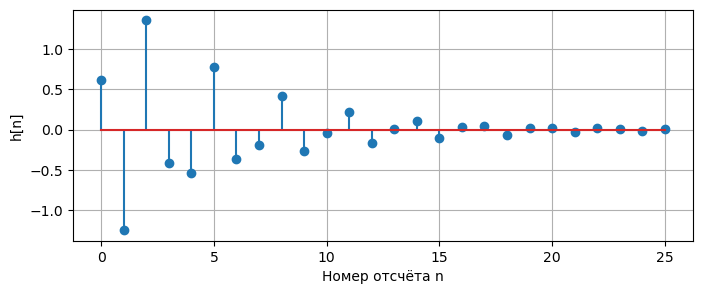

In [69]:
plt.figure(figsize=(8, 3))
plt.stem(np.arange(N1), h)
plt.xlabel('Номер отсчёта n')
plt.ylabel('h[n]')
plt.grid()
plt.show()

Передаточная функция:

$$H(z)=\frac{0.62-0.67518z^{-1}+0.62z^{-2}}{1+0.9278z^{-1}+0.676z^{-2}}.$$

При нулевых начальных условиях аналитическая формула имеет вид

$$h[n]=0.62g[n]-0.67518g[n-1]+0.62g[n-2],$$

где

$$g[n]=\begin{cases}
r^n\dfrac{\sin((n+1)\theta)}{\sin\theta},&n\geq0,\\
0,&n<0,
\end{cases}\qquad
r=\sqrt{0.676},\quad \theta=\arccos\left(-\frac{0.9278}{2r}\right).$$

Здесь $r\approx0.822192$, $\theta\approx0.6908243\pi$. Характеристика колеблется и затухает. Её действительная длина бесконечна, а $N_1=26$ задаёт только число рассчитанных отсчётов.

#### Реакция по формуле свёртки

Вычислить реакцию $y_1[n]$ по формуле свёртки. В качестве воздействия $x[n]$ длины $N_2$ выбрать дискретный прямоугольный импульс:

$$x[n]=\begin{cases}
1,&0\leq n<\operatorname{int}(N_2/2),\\
0,&\operatorname{int}(N_2/2)\leq n\leq N_2-1.
\end{cases}$$

Здесь $\operatorname{int}(t)$ - округление до ближайшего целого. Вывести графики воздействия и реакции. Пояснить:

- чему равна длина импульса $x$;
- чему равна длина свёртки аналитически и по графику;
- почему её ограничивают до длины воздействия.

In [70]:
# Первые 18 отсчётов равны единице, остальные - нулю
x1 = np.zeros(N2)
x1[:N2//2]=1

In [71]:
# Полная свёртка по сумме произведений
y1_full = np.zeros(N1 + N2 - 1)
for i in range(N2):
    for j in range(N1):
        y1_full[i + j] += x1[i] * h[j]

y1 = y1_full[:N2]

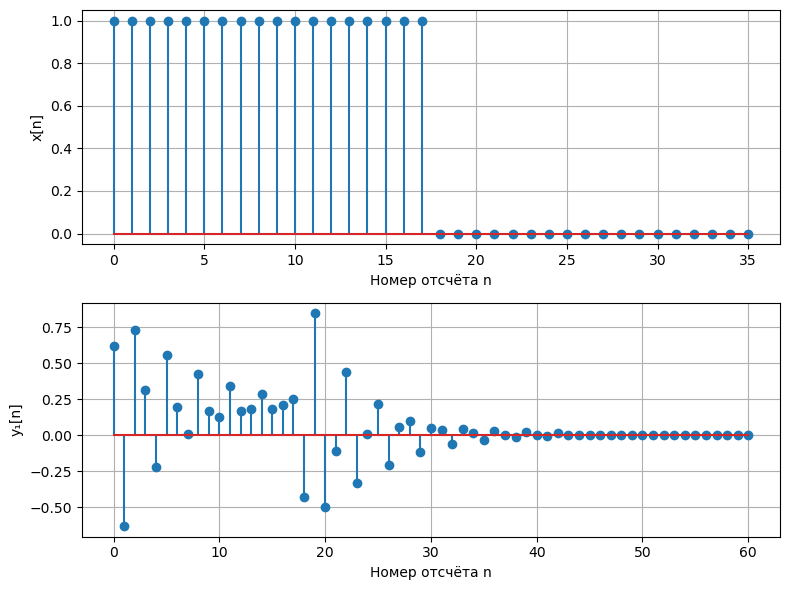

In [72]:
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.stem(np.arange(N2), x1)
plt.xlabel('Номер отсчёта n')
plt.ylabel('x[n]')
plt.grid()

plt.subplot(2, 1, 2)
plt.stem(np.arange(len(y1_full)), y1_full)
plt.xlabel('Номер отсчёта n')
plt.ylabel('y₁[n]')
plt.grid()
plt.tight_layout()
plt.show()

Массив $x[n]$ содержит $36$ отсчётов, ненулевая часть импульса - $18$ отсчётов. В этом варианте $N_2/2=18$, поэтому округление не требуется.

Длина полной свёртки равна $N_1+N_2-1=61$: индексы от $0$ до $60$. На графике ненулевая часть заканчивается при $n=42$, поскольку последний ненулевой отсчёт входа имеет индекс $17$, а последний отсчёт усечённой характеристики - $25$. Последующие $18$ элементов свёртки равны нулю.

Первые $36$ отсчётов выделяются для сравнения реакций на одном интервале наблюдения. Это не означает, что реакция системы заканчивается вместе с входным массивом.

#### Реакция по разностному уравнению

Вычислить реакцию $y_2[n]$ по разностному уравнению. Задать воздействие $x[n]$ из предыдущего пункта. Вывести графики воздействия и реакции. Сравнить графики реакций $y_1[n]$ и $y_2[n]$. Записать разностное уравнение рекурсивного звена 2-го порядка с заданными коэффициентами. Пояснить, чему равны длины воздействия и реакции.

Разностное уравнение:

$$y_2[n]=0.62x[n]-0.67518x[n-1]+0.62x[n-2]
-0.9278y_2[n-1]-0.676y_2[n-2].$$

Начальные условия: $x[-1]=x[-2]=y_2[-1]=y_2[-2]=0$.

In [73]:
# два нуля в начале задают значения при отрицательных индексах
x_pad = np.concatenate(([0, 0], x1))
y_pad = np.zeros(N2 + 2)

for n in range(2, N2 + 2):
    y_pad[n] = (b[0] * x_pad[n] + b[1] * x_pad[n - 1]
                + b[2] * x_pad[n - 2] - a[1] * y_pad[n - 1]
                - a[2] * y_pad[n - 2])
y2 = y_pad[2:]

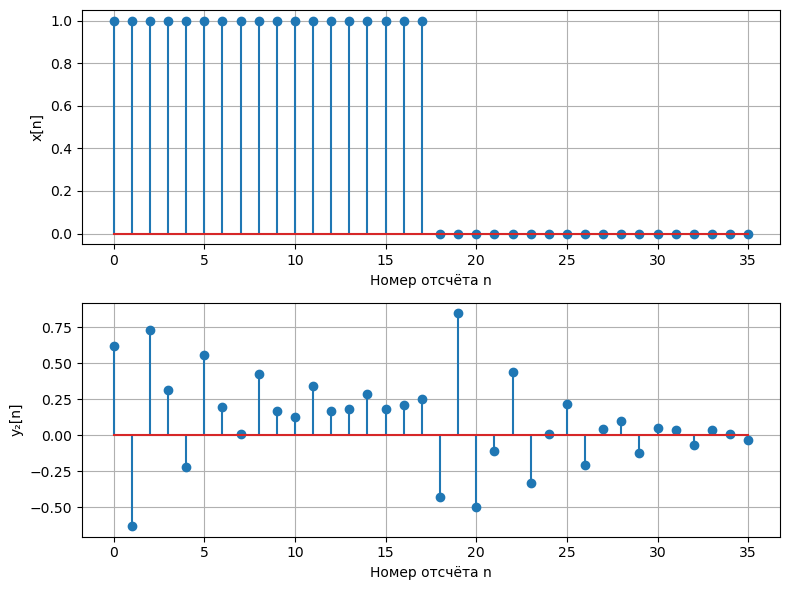

In [74]:
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.stem(np.arange(N2), x1)
plt.xlabel('Номер отсчёта n')
plt.ylabel('x[n]')
plt.grid()

plt.subplot(2, 1, 2)
plt.stem(np.arange(N2), y2)
plt.xlabel('Номер отсчёта n')
plt.ylabel('y₂[n]')
plt.grid()
plt.tight_layout()
plt.show()

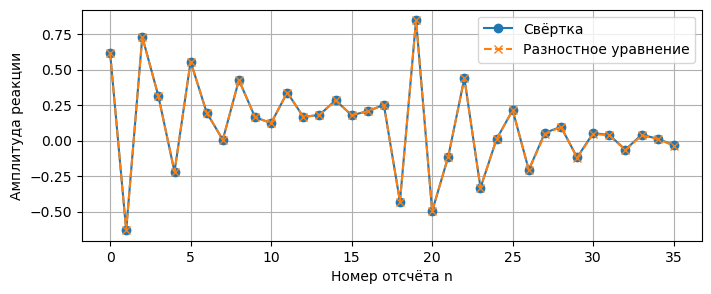

Наибольшее расхождение: 0.008791501134812377


In [75]:
# Сравнение на первых 36 отсчётах
plt.figure(figsize=(8, 3))
plt.plot(np.arange(N2), y1, 'o-', label='Свёртка')
plt.plot(np.arange(N2), y2, 'x--', label='Разностное уравнение')
plt.xlabel('Номер отсчёта n')
plt.ylabel('Амплитуда реакции')
plt.legend()
plt.grid()
plt.show()
print('Наибольшее расхождение:', np.max(np.abs(y1 - y2)))

На первых $26$ отсчётах реакции совпадают с точностью округления. Начиная с $n=26$ возникает расхождение, поскольку свёртка использует только $26$ отсчётов бесконечной импульсной характеристики. Максимальное расхождение составляет примерно $0.00879$. Для совпадения на всём интервале из $36$ отсчётов потребовалось бы использовать первые $36$ отсчётов $h[n]$.

Длины входного и рассчитанного выходного массивов равны $36$. Полная реакция рекурсивной системы бесконечна: после окончания импульса выход продолжает затухать.

#### Нули и полюсы передаточной функции

Вычислить нули и полюсы передаточной функции. Представить нули и полюсы в алгебраической и показательной формах и пояснить связь между ними. Выразить значение аргумента полюса и нуля относительно $\pi$. Представить передаточную функцию в виде произведения простейших множителей с нулями и полюсами в показательной форме.

In [76]:
# после умножения числителя и знаменателя на z^2 находятся корни полиномов
zeros = np.roots(b)
poles = np.roots(a)
print('Нули:', np.round(zeros, 8))
print('Полюсы:', np.round(poles, 8))

Нули: [0.5445+0.83876084j 0.5445-0.83876084j]
Полюсы: [-0.4639+0.67882015j -0.4639-0.67882015j]


In [77]:
# Модули и аргументы для показательной формы
print('Модули нулей:', np.round(np.abs(zeros), 8))
print('Аргументы нулей / π:', np.round(np.angle(zeros) / np.pi, 8))
print('Модули полюсов:', np.round(np.abs(poles), 8))
print('Аргументы полюсов / π:', np.round(np.angle(poles) / np.pi, 8))

Модули нулей: [1. 1.]
Аргументы нулей / π: [ 0.31671943 -0.31671943]
Модули полюсов: [0.82219219 0.82219219]
Аргументы полюсов / π: [ 0.6908243 -0.6908243]


Получены сопряжённые пары:

$$z_{1,2}=0.5445\pm j0.83876084\approx e^{\pm j0.31671943\pi},$$

$$p_{1,2}=-0.4639\pm j0.67882015\approx0.82219219e^{\pm j0.69082430\pi}.$$

Формы связаны равенством $x+jy=re^{j\theta}$, где $r=\sqrt{x^2+y^2}$, $\theta=\operatorname{atan2}(y,x)$. У сопряжённых корней модули одинаковы, аргументы противоположны. Нули с полюсами не совпадают.

С округлёнными значениями корней:

$$H(z)\approx0.62\,
\frac{(1-e^{j0.31671943\pi}z^{-1})(1-e^{-j0.31671943\pi}z^{-1})}
{(1-0.82219219e^{j0.69082430\pi}z^{-1})(1-0.82219219e^{-j0.69082430\pi}z^{-1})}.$$

#### Карта нулей и полюсов

Изобразить карту нулей и полюсов. Пояснить:

- является ли рекурсивное звено устойчивым;
- совпадают ли значения нулей и полюсов с вычисленными в предыдущем пункте.

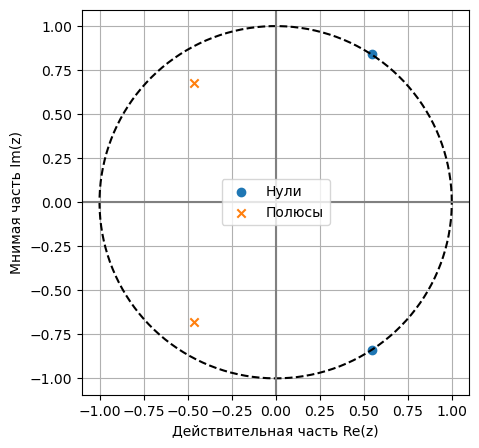

In [78]:
angle = np.linspace(0, 2 * np.pi, 300)

plt.figure(figsize=(5, 5))
plt.plot(np.cos(angle), np.sin(angle), 'k--')
plt.scatter(zeros.real, zeros.imag, marker='o', label='Нули')
plt.scatter(poles.real, poles.imag, marker='x', label='Полюсы')
plt.axhline(0, color='gray')
plt.axvline(0, color='gray')
plt.xlabel('Действительная часть Re(z)')
plt.ylabel('Мнимая часть Im(z)')
plt.axis('equal')
plt.legend()
plt.grid()
plt.show()

Оба полюса находятся внутри единичной окружности: $|p_{1,2}|\approx0.82219219<1$. Следовательно, звено устойчиво. Нули лежат на единичной окружности. Координаты всех точек совпадают с вычисленными значениями, по которым построена карта.

#### АЧХ и ФЧХ в нормированной шкале

Вычислить амплитудно-частотную и фазочастотную характеристики в шкале нормированных частот $\widehat\omega$ и вывести их графики. Пояснить:

- чему равны границы основной полосы частот;
- соответствие между картой нулей и полюсов и видом АЧХ;
- какому значению АЧХ соответствует скачок на $\pi$, если он имеется;
- какие частотные составляющие воздействия, низкие или высокие, оказались преимущественно подавленными в реакции.

In [79]:
w = np.linspace(0, np.pi, 1000)
# Частота нуля добавлена в сетку, чтобы не показывать фазу в этой точке
w = np.sort(np.append(w, abs(np.angle(zeros[0]))))
w, H = signal.freqz(b, a, worN=w)
amplitude = np.abs(H)
phase = np.angle(H)
phase[amplitude < 1e-10] = np.nan

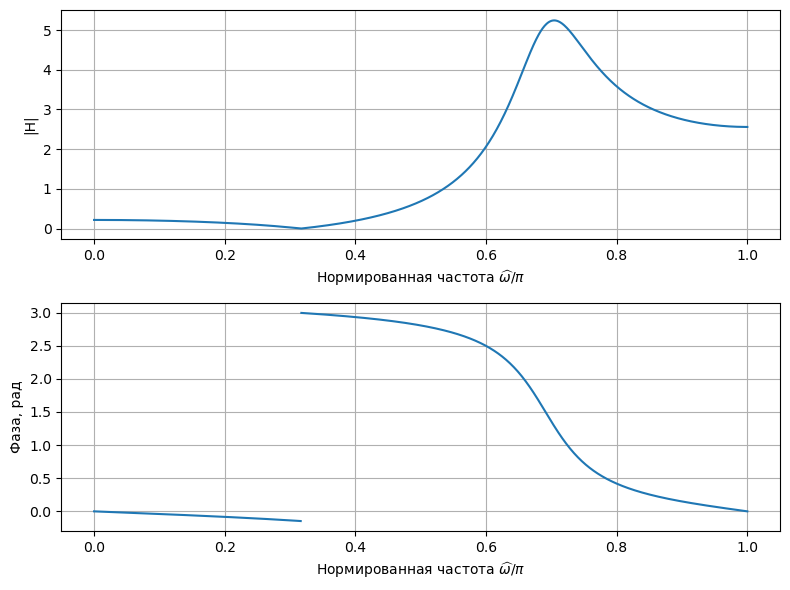

In [80]:
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.plot(w / np.pi, amplitude)
plt.xlabel(r'Нормированная частота $\widehat{\omega}/\pi$')
plt.ylabel('|H|')
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(w / np.pi, phase)
plt.xlabel(r'Нормированная частота $\widehat{\omega}/\pi$')
plt.ylabel('Фаза, рад')
plt.grid()
plt.tight_layout()
plt.show()

Основная полоса составляет $[-\pi;\pi)$; показана её половина $[0;\pi]$, поскольку коэффициенты вещественные. На оси отложено $\widehat\omega/\pi$.

Нули на единичной окружности дают провал АЧХ при $\widehat\omega\approx0.31671943\pi$. Вблизи аргументов полюсов наблюдается подъём АЧХ. Максимум может быть немного смещён относительно аргумента полюса, так как зависит и от положения нулей.

Скачок фазы на $\pi$ возникает при прохождении через нуль АЧХ. В этой точке фаза не определена. Это величина скачка, а не указание частоты $\widehat\omega=\pi$.

Низкие частоты подавляются сильнее высоких частот в области подъёма АЧХ. Поэтому прямоугольное воздействие изменяет форму, а в реакции появляются колебания.

#### АЧХ и ФЧХ в герцах

Вычислить АЧХ и ФЧХ в шкале частот $f$ (Гц) при заданной частоте дискретизации и вывести их графики. Пояснить:

- чему равны границы основной полосы частот;
- соответствие между частотами $\widehat\omega$ и $f$.

In [81]:
# та же характеристика частотная ось переведена в герцы
f_hz = w * fs1 / (2 * np.pi)

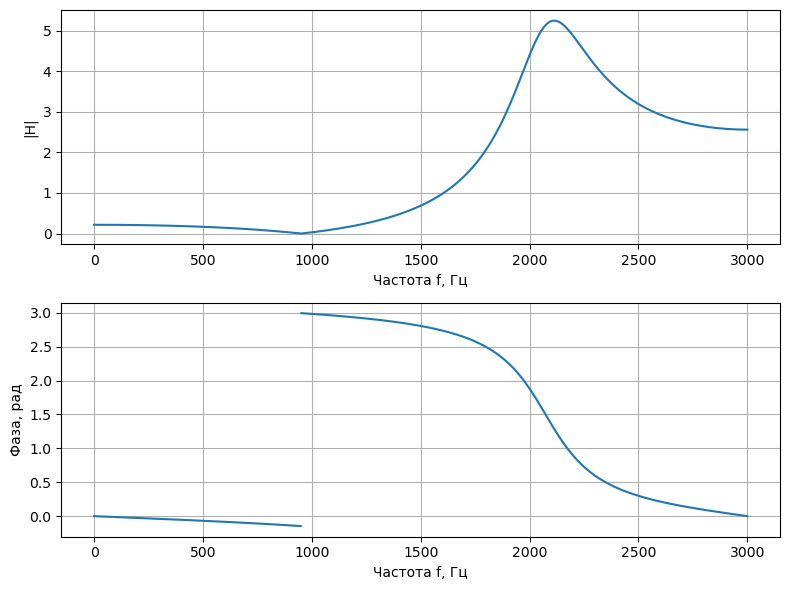

In [82]:
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.plot(f_hz, amplitude)
plt.xlabel('Частота f, Гц')
plt.ylabel('|H|')
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(f_hz, phase)
plt.xlabel('Частота f, Гц')
plt.ylabel('Фаза, рад')
plt.grid()
plt.tight_layout()
plt.show()

При $f_s=6000$ Гц основная полоса равна $[-3000;3000)$ Гц, на графиках показана половина от $0$ до $3000$ Гц. Частоты связаны формулой

$$f=\frac{\widehat\omega f_s}{2\pi}=3000\frac{\widehat\omega}{\pi}.$$

Форма характеристик сохраняется, меняется только масштаб оси частот.

### Часть 2

Данные варианта 6: $N=64$, $f_s=4000$ Гц, $T=0.00025$ с, $A_1=1.06$, $A_2=2.12$, $f_1=500$ Гц, $f_2=750$ Гц.

In [83]:
N = 64
fs2 = 4000
T = 1 / fs2
A1 = 1.06
A2 = 2.12
f1 = 500
f2 = 750

#### Последовательность в двух шкалах времени

Вывести графики последовательности $x[n]$ на периоде $N$ в шкале дискретного и дискретного нормированного времени:

$$x(nT)=A_1\cos(2\pi f_1nT+\pi/4)+A_2\cos(2\pi f_2nT+\pi/8).$$

In [84]:
n = np.arange(N) #
t_samples = n * T
x = (A1 * np.cos(2 * np.pi * f1 * t_samples + np.pi / 4)
     + A2 * np.cos(2 * np.pi * f2 * t_samples + np.pi / 8))

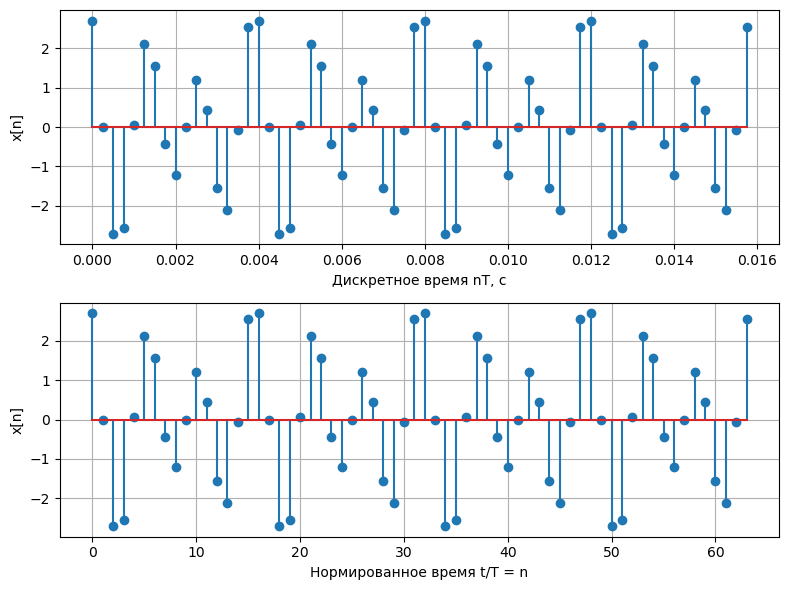

In [85]:
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.stem(t_samples, x)
plt.xlabel('Дискретное время nT, с')
plt.ylabel('x[n]')
plt.grid()

plt.subplot(2, 1, 2)
plt.stem(n, x)
plt.xlabel('Нормированное время t/T = n')
plt.ylabel('x[n]')
plt.grid()
plt.tight_layout()
plt.show()

Графики показывают одни и те же $64$ отсчёта. В первой шкале шаг равен $T=0.00025$ с, во второй - единице.

#### Обратное ДПФ

Вычислить ОДПФ от ДПФ последовательности $x[n]$ и вывести график полученной последовательности в шкале дискретного нормированного времени.

In [86]:
# прямое и обратное преобразованиz
X = np.fft.fft(x)
x_back = np.fft.ifft(X).real

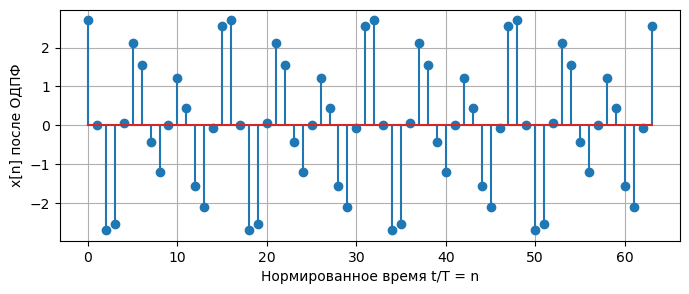

In [87]:
plt.figure(figsize=(8, 3))
plt.stem(n, x_back)
plt.xlabel('Нормированное время t/T = n')
plt.ylabel('x[n] после ОДПФ')
plt.grid()
plt.show()

После ОДПФ получена исходная последовательность с точностью вычислительного округления.

#### Амплитудный и фазовый спектры

Вычислить амплитудный и фазовый спектры последовательности $x[n]$ и вывести их графики в шкалах дискретных нормированных и абсолютных частот. Пояснить:

- связь дискретного нормированного времени с дискретным временем;
- связь частоты $f$ (Гц) с дискретной нормированной частотой;
- вид амплитудного и фазового спектров.

In [88]:
# fftshift переносит отрицательные частоты в левую часть графика
f = np.fft.fftshift(np.fft.fftfreq(N, d=T))
wn = 2 * np.pi * f / fs2
C = np.fft.fftshift(X) / N
amp = np.abs(C)
phi = np.angle(C)

# Фаза показывается только у ненулевых составляющих
mask = amp > 1e-10

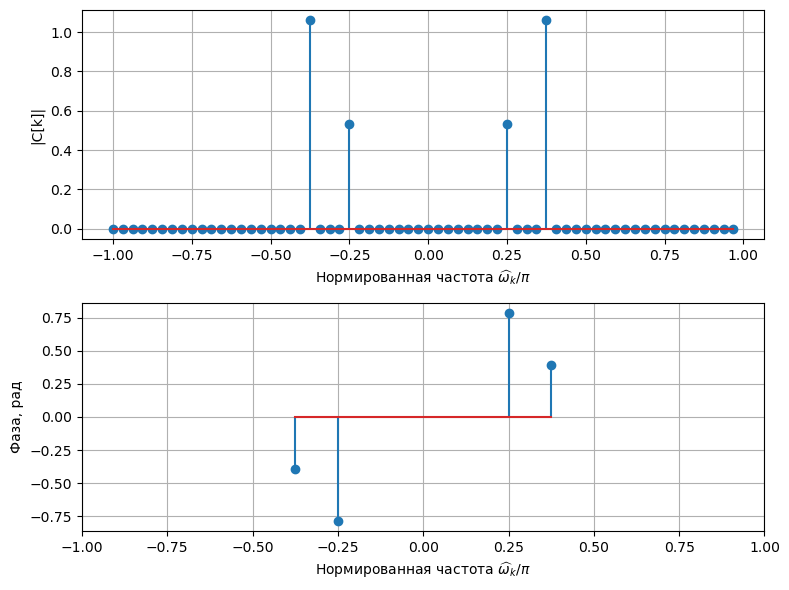

In [89]:
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.stem(wn / np.pi, amp)
plt.xlabel(r'Нормированная частота $\widehat{\omega}_k/\pi$')
plt.ylabel('|C[k]|')
plt.grid()

plt.subplot(2, 1, 2)
plt.stem(wn[mask] / np.pi, phi[mask])
plt.xlim(-1, 1)
plt.xlabel(r'Нормированная частота $\widehat{\omega}_k/\pi$')
plt.ylabel('Фаза, рад')
plt.grid()
plt.tight_layout()
plt.show()

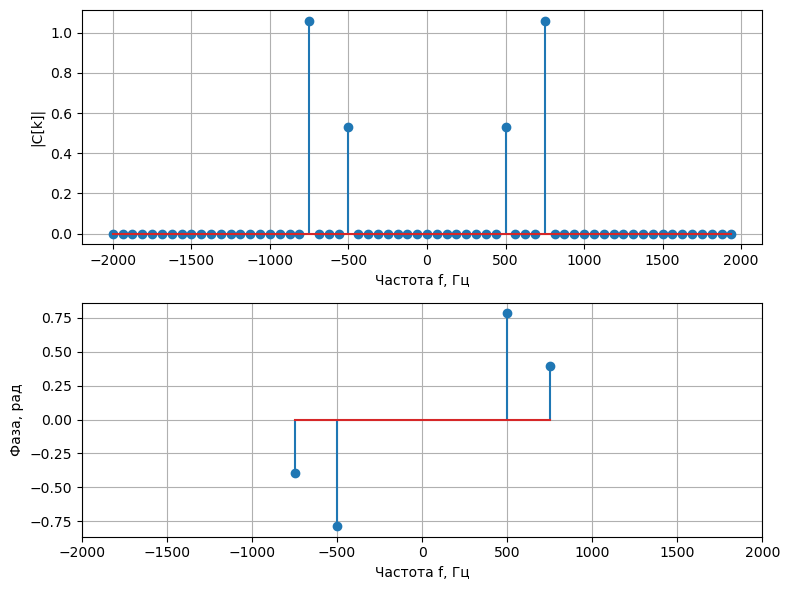

In [90]:
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.stem(f, amp)
plt.xlabel('Частота f, Гц')
plt.ylabel('|C[k]|')
plt.grid()

plt.subplot(2, 1, 2)
plt.stem(f[mask], phi[mask])
plt.xlim(-fs2 / 2, fs2 / 2)
plt.xlabel('Частота f, Гц')
plt.ylabel('Фаза, рад')
plt.grid()
plt.tight_layout()
plt.show()

Нормированное время равно $t/T=n$, а нормированная частота - $\widehat\omega=2\pi f/f_s$. Для отсчётов спектра $f_k=kf_s/N$ и $\widehat\omega_k=2\pi k/N$.

В двустороннем спектре получены линии:

- при $f=\pm500$ Гц, или $\widehat\omega/\pi=\pm0.25$: амплитуды $0.53$, фазы $\pm\pi/4$;
- при $f=\pm750$ Гц, или $\widehat\omega/\pi=\pm0.375$: амплитуды $1.06$, фазы $\pm\pi/8$.

Амплитудный спектр симметричен, а фазы противоположных частот имеют разные знаки. Две сопряжённые линии соответствуют одной косинусоиде, поэтому амплитуда каждой линии вдвое меньше амплитуды косинусоиды. Частоты совпадают с узлами ДПФ, и на блоке укладывается целое число периодов обеих гармоник. Остальные отсчёты ДПФ равны нулю с точностью округления; фаза в этих точках не определяется.

#### ДПФ конечной последовательности и спектр периодической последовательности

Вычислить ДПФ конечной последовательности $x[n]$ длины $N$. Вывести графики в шкале дискретных нормированных частот модуля ДПФ конечной последовательности и амплитудного спектра периодической последовательности. Пояснить связь модуля ДПФ конечной последовательности с амплитудным спектром периодической последовательности.

In [91]:
# тот же блок рассматривается как конечная последовательность
X_finite = np.fft.fft(x)
X_finite_shifted = np.fft.fftshift(X_finite)

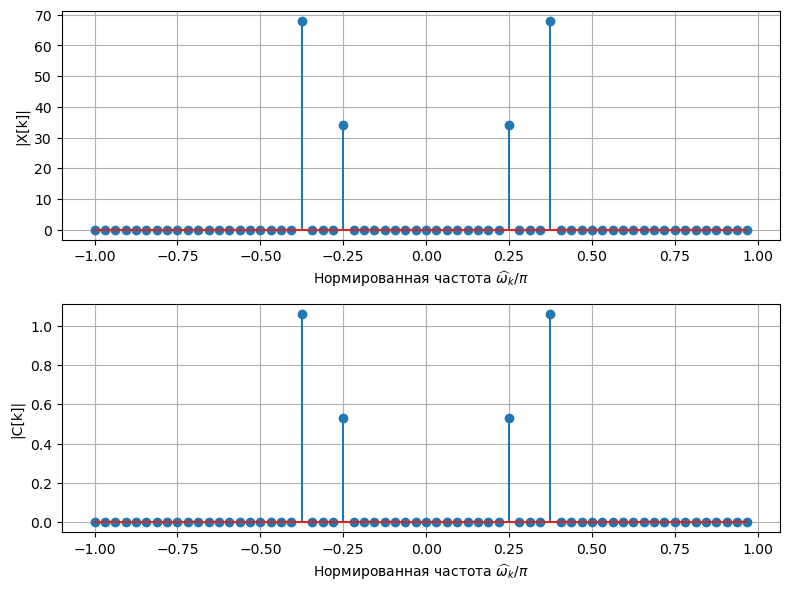

In [92]:
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.stem(wn / np.pi, np.abs(X_finite_shifted))
plt.xlabel(r'Нормированная частота $\widehat{\omega}_k/\pi$')
plt.ylabel('|X[k]|')
plt.grid()

plt.subplot(2, 1, 2)
plt.stem(wn / np.pi, amp)
plt.xlabel(r'Нормированная частота $\widehat{\omega}_k/\pi$')
plt.ylabel('|C[k]|')
plt.grid()
plt.tight_layout()
plt.show()

Частоты линий совпадают. Для периодической последовательности $C[k]=X[k]/N$, поэтому $|X[k]|=64|C[k]|$. Ненулевые модули ДПФ равны $33.92$ и $67.84$, а двусторонние амплитуды периодической последовательности - $0.53$ и $1.06$.

ДПФ конечной записи даёт отсчёты её спектра в заданных частотных узлах. В периодическом случае коэффициенты $C[k]$ задают линии спектра периодического продолжения.

#### Восстановление аналогового сигнала

Восстановить периодический аналоговый сигнал $x(t)$ по отсчётам ДПФ $X[k]$ периодической последовательности $x[n]$. Для вычисления значений сигнала использовать формулу

$$x(t)=\frac{1}{N}\sum_{k=-N/2}^{N/2-1}X_a[k]\exp\left(j\frac{2\pi}{NT}kt\right),$$

где

$$X_a[k]=\begin{cases}
X[N+k],&-N/2\leq k\leq-1,\\
X[k],&0\leq k\leq N/2-1.
\end{cases}$$

Задать время на интервале $t\in[0;(N-1)T]$ с шагом $\Delta t=0.25T$. Вывести графики:

- периодической последовательности $x[n]$ и модуля её ДПФ;
- восстановленного аналогового сигнала $x(t)$ и его амплитудного спектра;
- исходного аналогового сигнала $x(t)=A_1\cos(2\pi f_1t+\pi/4)+A_2\cos(2\pi f_2t+\pi/8)$.

In [93]:
# Время от 0 до (N - 1)T включительно с шагом T/4
t = np.arange(4 * (N - 1) + 1) * T / 4
k = np.arange(-N // 2, N // 2)
Xa = np.fft.fftshift(X)

In [94]:
# Сумма из формулы восстановления
x_restored = np.zeros(len(t), dtype=complex)
for i in range(N):
    x_restored += Xa[i] * np.exp(1j * 2 * np.pi * k[i] * t / (N * T))

x_restored = (x_restored / N).real

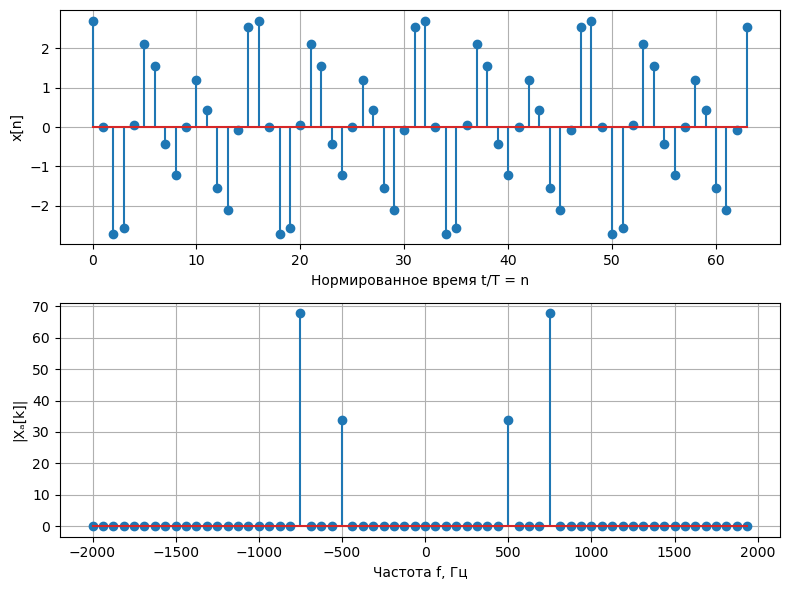

In [95]:
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.stem(n, x)
plt.xlabel('Нормированное время t/T = n')
plt.ylabel('x[n]')
plt.grid()

plt.subplot(2, 1, 2)
plt.stem(f, np.abs(Xa))
plt.xlabel('Частота f, Гц')
plt.ylabel('|Xₐ[k]|')
plt.grid()
plt.tight_layout()
plt.show()

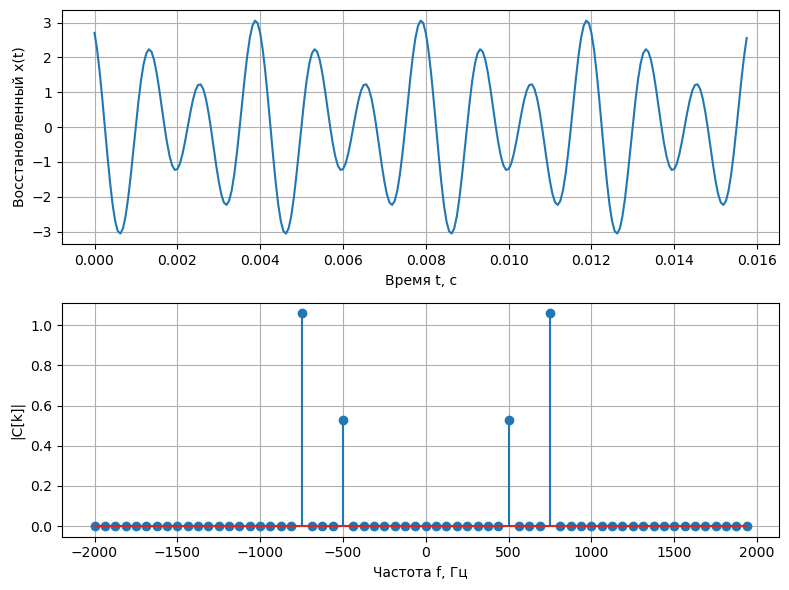

In [96]:
plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.plot(t, x_restored)
plt.xlabel('Время t, с')
plt.ylabel('Восстановленный x(t)')
plt.grid()

plt.subplot(2, 1, 2)
plt.stem(f, np.abs(Xa) / N)
plt.xlabel('Частота f, Гц')
plt.ylabel('|C[k]|')
plt.grid()
plt.tight_layout()
plt.show()

In [97]:
x_original = (A1 * np.cos(2 * np.pi * f1 * t + np.pi / 4)
              + A2 * np.cos(2 * np.pi * f2 * t + np.pi / 8))

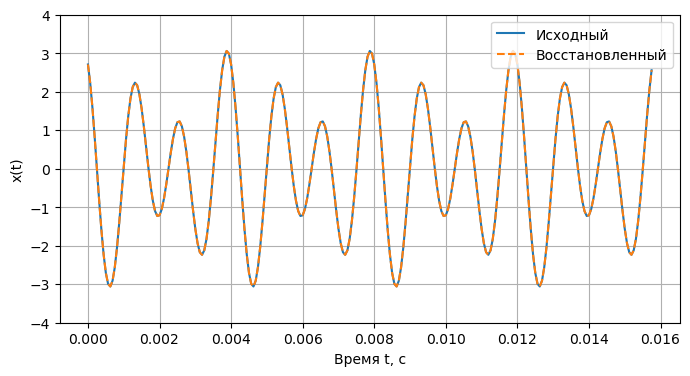

In [98]:
# Исходный сигнал и восстановленный сигнал для сравнения
plt.figure(figsize=(8, 4))
plt.plot(t, x_original, label='Исходный')
plt.plot(t, x_restored, '--', label='Восстановленный')
plt.xlabel('Время t, с')
plt.ylabel('x(t)')
plt.legend(loc='upper right')
plt.ylim(-4, 4)
plt.grid()
plt.show()

#### Сравнение исходного и восстановленного сигналов

Исходя из результатов восстановления, объяснить:

- связь модуля ДПФ последовательности со спектром аналогового сигнала;
- результат визуального сравнения восстановленного и исходного сигналов.

Коэффициенты ряда Фурье аналогового сигнала равны $X_a[k]/N$. Поэтому модуль ДПФ необходимо разделить на $64$: получаются линии амплитуды $0.53$ на частотах $\pm500$ Гц и $1.06$ на частотах $\pm750$ Гц. На графике спектра показаны веса линий, а не высота дельта-функций.

Исходный и восстановленный сигналы визуально совпадают. Частоты $500$ и $750$ Гц ниже частоты Найквиста $2000$ Гц и точно лежат на сетке ДПФ. Формула восстановления сохраняет амплитуды и фазы обеих гармоник. Различия остаются только на уровне вычислительного округления.

#### Равенство Парсеваля

Проверить равенство Парсеваля. Пояснить его смысл.

In [99]:
# Левая и правая части равенства Парсеваля
energy_time = np.sum(np.abs(x)**2)
energy_frequency = np.sum(np.abs(X)**2) / N

print('Во временной области:', energy_time)
print('В частотной области:', energy_frequency)

Во временной области: 179.776
В частотной области: 179.776


Получено

$$\sum_{n=0}^{63}|x[n]|^2=\frac{1}{64}\sum_{k=0}^{63}|X[k]|^2=179.776.$$

Равенство выполнено с точностью вычислений. Сумма квадратов отсчётов сохраняется при переходе к частотному представлению с учётом множителя $1/N$. Здесь рассматривается конечный блок из $64$ отсчётов, а не полная энергия бесконечного периодического сигнала.

## Выводы

Рассчитана импульсная характеристика звена второго порядка и получена его реакция на прямоугольный импульс. Характеристика бесконечна и затухает. Свёртка с её первыми $26$ отсчётами совпала с разностным уравнением на первых $26$ отсчётах реакции. Далее возникло расхождение из-за усечения характеристики. Длина полного массива свёртки составила $61$, длина массива реакции по разностному уравнению - $36$.

Звено устойчиво, поскольку модули полюсов меньше единицы. Нули на единичной окружности соответствуют провалу АЧХ и скачку фазы на $\pi$. Вблизи полюсов наблюдается подъём АЧХ; низкие частоты подавляются сильнее частот этой области.

ДПФ выявило две гармоники с частотами $500$ и $750$ Гц. Двусторонний спектр содержит сопряжённые линии с амплитудами $0.53$ и $1.06$. ОДПФ вернуло исходные отсчёты, а восстановление по комплексным экспонентам - исходный аналоговый сигнал с точностью округления. Равенство Парсеваля выполнено: обе суммы равны $179.776$.